# 07. Доп. задание 2 - скошенный таргет и асимметричная стоимость ошибки

**Датасет:** freMTPL2 (французское страхование автогражданской ответственности, R-пакет CASdatasets):
678 тыс. полисов (`freMTPL2freq`) и 26 тыс. выплат (`freMTPL2sev`).

**Таргет:** `ClaimAmount` - сумма выплат по полису за период действия (евро). Большинство полисов без выплат,
а редкие выплаты достигают миллионов - классический скошенный таргет с нулями.

**Бизнес-постановка.** Страховщик прогнозирует ожидаемые выплаты по полису, чтобы назначить премию.
- **Недооценка** риска (ŷ < y) - премия меньше убытка, прямой убыток компании;
- **переоценка** (ŷ > y) - завышенная цена, клиент уходит к конкуренту (упущенная выгода).
Принимаем, что недооценка в **5 раз дороже** переоценки. Кроме того, для страховщика важно, чтобы
**сумма** прогнозов по портфелю совпадала с суммой реальных выплат (`Σŷ / Σy ≈ 1`).

**Протокол.** 5-фолдовая CV (`KFold`, shuffle, seed 42): для каждого полиса - out-of-fold прогноз модели,
которая его не видела. Всё, что «учится» (квантиль винзоризации, параметры Yeo-Johnson, поправка смещения,
пороги весов), считается **только на train-фолде**. Метрики - **на исходной шкале** в евро.

In [1]:
import sys
from pathlib import Path

KAGGLE_CONFIG_PATHS = [
    Path("/kaggle/input/project-config"),
    Path("/kaggle/input/kirylloffix/project-config"),
]

for p in KAGGLE_CONFIG_PATHS:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
        break

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, het_white
from statsmodels.stats.outliers_influence import OLSInfluence

from config import Config


warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

config = Config()
RANDOM_STATE = config.RANDOM_STATE
np.random.seed(RANDOM_STATE)
print(config)

Config(mode='local', credit='/home/claude/proj/data/credit_risk_dataset.csv', churn='/home/claude/proj/data/WA_Fn-UseC_-Telco-Customer-Churn.csv', demand='/home/claude/proj/data/train.csv', random_state=42)


In [2]:
DATASET = 'skewed'
UNDER_COST = 5.0

freq = pd.read_csv(config.path_claims_freq)
sev = pd.read_csv(config.path_claims_sev)
claims = sev.groupby('IDpol')['ClaimAmount'].sum()

df = freq.merge(claims.rename('ClaimAmount'), left_on='IDpol', right_index=True, how='left')
df['ClaimAmount'] = df['ClaimAmount'].fillna(0.0)

print(f"полисов: {len(freq)}, выплат: {len(sev)}, полисов с выплатами: {len(claims)}")
print(f"ClaimNb > 0 без записи о выплате: {((df['ClaimNb'] > 0) & (df['ClaimAmount'] == 0)).sum()}")
df.head()

полисов: 677991, выплат: 26444, полисов с выплатами: 24944
ClaimNb > 0 без записи о выплате: 0


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region,ClaimAmount
0,1.0,0.0,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes,0.0
1,3.0,0.0,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes,0.0
2,5.0,0.0,0.75,6,2,52,50,B12,Diesel,B,54,Picardie,0.0
3,10.0,0.0,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine,0.0
4,11.0,0.0,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine,0.0


## Правила очистки

- `Exposure > 1` (1 224 полиса, до 2.01 года) - для годовых полисов невозможно -> обрезаем до 1;
- `Density` - логарифмируем (разброс 1 - 27 000 чел/км²);
- категориальные признаки - тип `category` (LightGBM работает с ними нативно);
- сам таргет **не трогаем**: обрезка выбросов - отдельный эксперимент (винзоризация).

In [3]:
print(f"Exposure > 1: {(df['Exposure'] > 1).sum()}")
df['Exposure'] = df['Exposure'].clip(upper=1.0)
df['LogDensity'] = np.log(df['Density'])

NUM = ['VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'LogDensity', 'Exposure']
CAT = ['VehBrand', 'VehGas', 'Area', 'Region']
for c in CAT:
    df[c] = df[c].astype('category')

X = df[NUM + CAT]
y = df['ClaimAmount'].to_numpy(dtype=float)
print(X.shape)

Exposure > 1: 1224


(677991, 10)


## 1. Диагностика скошенности

In [4]:
pos = y[y > 0]
diag = {
    'полисов': len(y),
    'доля нулей': (y == 0).mean(),
    'среднее': y.mean(),
    'медиана': np.median(y),
    'skewness': stats.skew(y),
    'kurtosis (excess)': stats.kurtosis(y),
    'медиана ненулевых': np.median(pos),
    'q90 ненулевых': np.quantile(pos, 0.90),
    'q99 ненулевых': np.quantile(pos, 0.99),
    'максимум': y.max(),
    'skewness log1p(y>0)': stats.skew(np.log1p(pos)),
}
srt = np.sort(pos)[::-1]
diag['доля суммы: верхний 1% выплат'] = srt[:int(0.01 * len(pos))].sum() / y.sum()
diag['доля суммы: верхние 10% выплат'] = srt[:int(0.10 * len(pos))].sum() / y.sum()
diag['доля суммы: 1 крупнейшая выплата'] = srt[0] / y.sum()
diag_s = pd.Series(diag)
diag_s.to_csv(config.RESULTS_DIR / 'skewed_diagnostics.csv', header=['value'])
print(diag_s.apply(lambda v: f"{v:,.4f}" if abs(v) < 100 else f"{v:,.0f}").to_string())

полисов                               677,991
доля нулей                             0.9632
среднее                               88.3628
медиана                                0.0000
skewness                                  550
kurtosis (excess)                     363,244
медиана ненулевых                       1,172
q90 ненулевых                           3,000
q99 ненулевых                          18,278
максимум                            4,075,401
skewness log1p(y>0)                   -0.5124
доля суммы: верхний 1% выплат          0.3786
доля суммы: верхние 10% выплат         0.6020
доля суммы: 1 крупнейшая выплата       0.0680

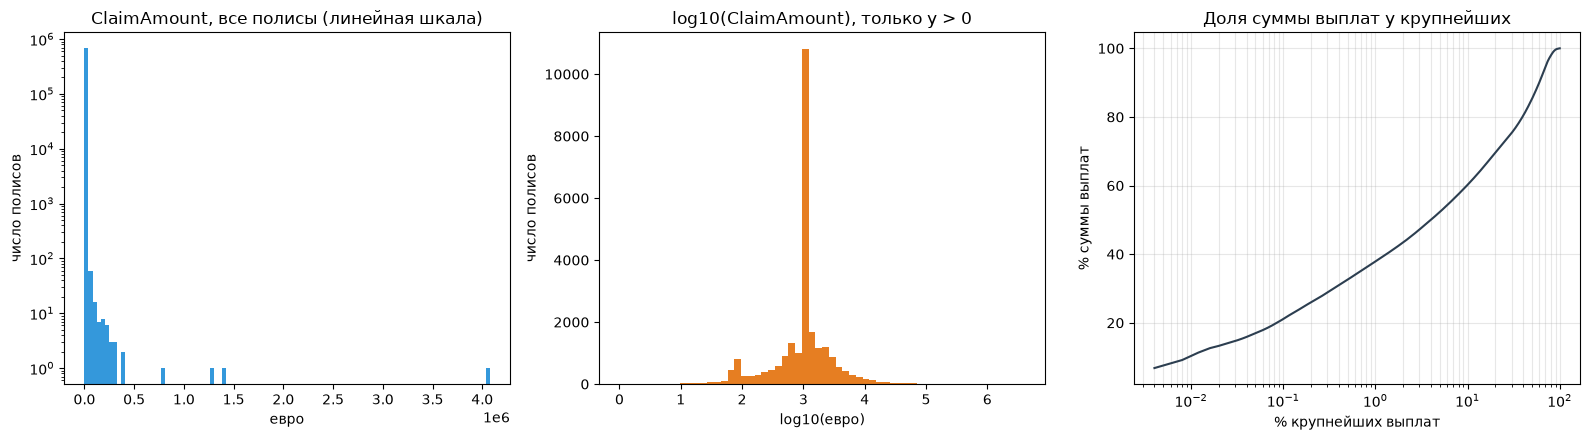

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(y, bins=100, color='#3498db')
axes[0].set(title='ClaimAmount, все полисы (линейная шкала)', xlabel='евро', ylabel='число полисов', yscale='log')
axes[1].hist(np.log10(pos), bins=60, color='#e67e22')
axes[1].set(title='log10(ClaimAmount), только y > 0', xlabel='log10(евро)', ylabel='число полисов')
cum = np.cumsum(srt) / srt.sum()
axes[2].plot(np.arange(1, len(srt) + 1) / len(srt) * 100, cum * 100, color='#2c3e50')
axes[2].set(title='Доля суммы выплат у крупнейших', xlabel='% крупнейших выплат', ylabel='% суммы выплат', xscale='log')
axes[2].grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'skewed_target_hist.png', dpi=150)
plt.show()

### Остатки линейной модели: гетероскедастичность, QQ-plot, Cook's distance

Для классической диагностики строим OLS (`statsmodels`) на случайных 50 000 полисах:
числовые признаки (стандартизованы) + OneHot категорий.

- **Breusch-Pagan:** регрессия квадратов остатков на признаки; H₀ - дисперсия ошибки постоянна (гомоскедастичность).
  Считаем три варианта: робастный (Коэнкер, по умолчанию в `statsmodels`), классический (предполагает нормальность
  ошибок) и по прогнозу (регрессоры - ŷ и ŷ²).
- **White:** то же, но с квадратами и попарными произведениями признаков (ловит нелинейную гетероскедастичность);
  считаем на числовых признаках, чтобы число регрессоров было разумным.
- **QQ-plot:** квантили остатков против квантилей нормального распределения.
- **Cook's distance:** насколько изменятся все прогнозы, если выкинуть объект; порог «влиятельности» - 4/n.

In [6]:
rng = np.random.RandomState(RANDOM_STATE)
idx = rng.choice(len(df), 50_000, replace=False)
sub = df.iloc[idx]
Xn = (sub[NUM] - sub[NUM].mean()) / sub[NUM].std()
Xd = pd.get_dummies(sub[CAT], drop_first=True, dtype=float)
exog = sm.add_constant(pd.concat([Xn, Xd], axis=1))
ys = sub['ClaimAmount'].to_numpy()

ols = sm.OLS(ys, exog).fit()
resid, fitted = ols.resid, ols.fittedvalues

bp_lm, bp_p, _, _ = het_breuschpagan(resid, exog)                      # вариант Коэнкера (робастный)
bpc_lm, bpc_p, _, _ = het_breuschpagan(resid, exog, robust=False)       # классический BP (нормальность ошибок)
fit_exog = sm.add_constant(np.column_stack([fitted, fitted ** 2]))
bpf_lm, bpf_p, _, _ = het_breuschpagan(resid, fit_exog, robust=False)   # дисперсия vs прогноз
w_lm, w_p, _, _ = het_white(resid, sm.add_constant(Xn))
infl = OLSInfluence(ols)
cooks = infl.cooks_distance[0]
thr_cook = 4 / len(ys)

het = pd.Series({
    'R2 OLS': ols.rsquared,
    'BP (Koenker) LM': bp_lm, 'BP (Koenker) p-value': bp_p,
    'BP классический LM': bpc_lm, 'BP классический p-value': bpc_p,
    'BP по прогнозу LM': bpf_lm, 'BP по прогнозу p-value': bpf_p,
    'White LM': w_lm, 'White p-value': w_p,
    'Jarque-Bera остатков': stats.jarque_bera(resid).statistic,
    "Cook's D > 4/n, объектов": (cooks > thr_cook).sum(),
    "из них с y > 0, доля": (ys[cooks > thr_cook] > 0).mean(),
    "y у 10 самых влиятельных (медиана)": np.median(ys[np.argsort(cooks)[-10:]]),
})
het.to_csv(config.RESULTS_DIR / 'skewed_heteroscedasticity.csv', header=['value'])
print(het.apply(lambda v: f"{v:.4g}").to_string())

R2 OLS                                 0.002537
BP (Koenker) LM                            28.4
BP (Koenker) p-value                     0.9578
BP классический LM                    7.118e+04
BP классический p-value                       0
BP по прогнозу LM                     5.499e+04
BP по прогнозу p-value                        0
White LM                                  39.51
White p-value                           0.05687
Jarque-Bera остатков                  5.236e+10
Cook's D > 4/n, объектов                    300
из них с y > 0, доля                          1
y у 10 самых влиятельных (медиана)    3.908e+04


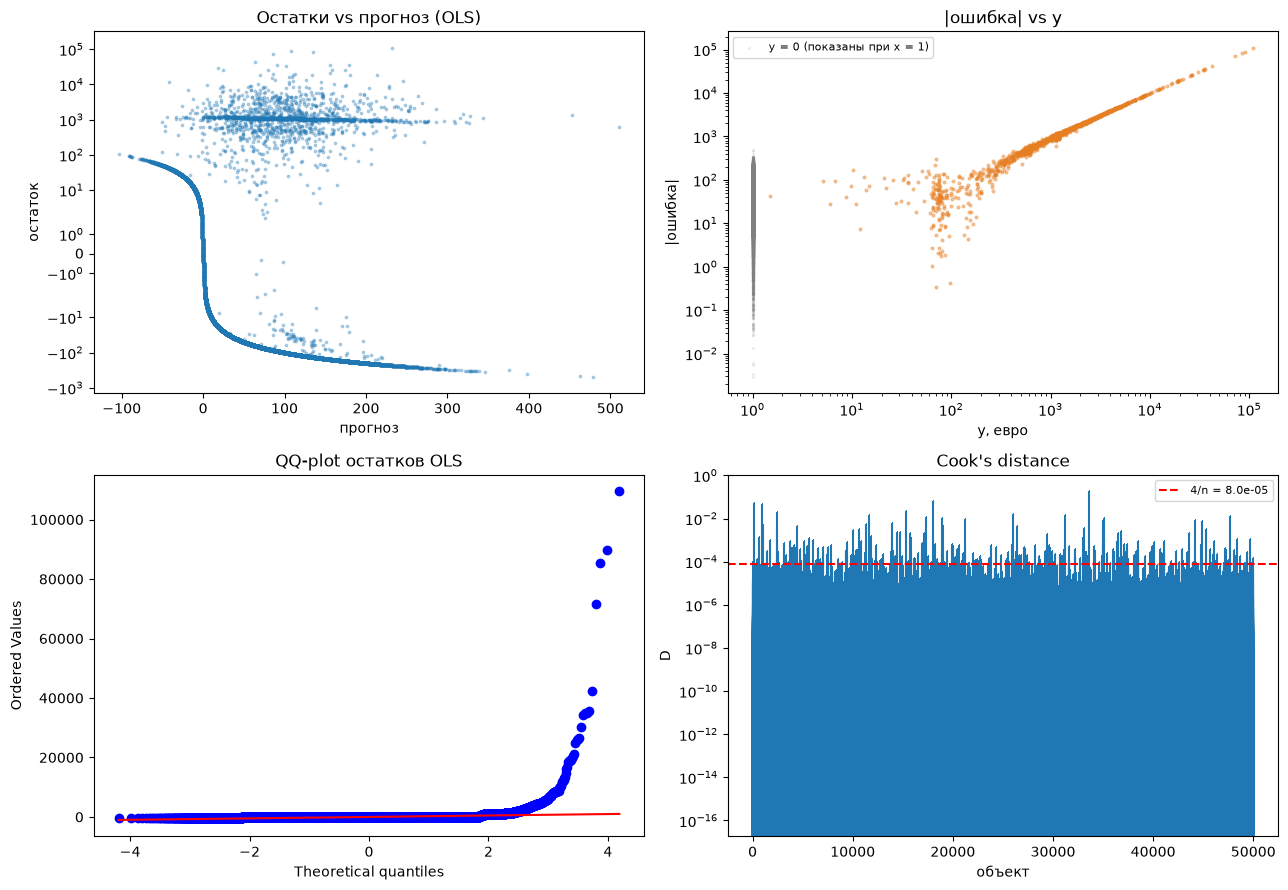

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].scatter(fitted, resid, s=3, alpha=0.3)
axes[0, 0].set(title='Остатки vs прогноз (OLS)', xlabel='прогноз', ylabel='остаток', yscale='symlog')

err_pos = np.abs(resid[ys > 0])
axes[0, 1].scatter(ys[ys > 0], err_pos, s=4, alpha=0.4, color='#e67e22')
axes[0, 1].scatter(np.full((ys == 0).sum(), 1.0), np.abs(resid[ys == 0]), s=2, alpha=0.1, color='grey', label='y = 0 (показаны при x = 1)')
axes[0, 1].set(title='|ошибка| vs y', xlabel='y, евро', ylabel='|ошибка|', xscale='log', yscale='log')
axes[0, 1].legend(fontsize=8)

stats.probplot(resid, dist='norm', plot=axes[1, 0])
axes[1, 0].set(title='QQ-plot остатков OLS')

axes[1, 1].stem(np.arange(len(cooks)), cooks, markerfmt=',', basefmt=' ')
axes[1, 1].axhline(thr_cook, color='red', ls='--', label=f'4/n = {thr_cook:.1e}')
axes[1, 1].set(title="Cook's distance", xlabel='объект', ylabel='D', yscale='log')
axes[1, 1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'skewed_residual_diagnostics.png', dpi=150)
plt.show()

## 2. Эксперименты

Одинаковый LightGBM (300 деревьев, `learning_rate=0.05`, `num_leaves=31`, `min_child_samples=200`) - меняется только
**таргет, функция потерь или веса**. Плюс константы и линейная модель как ориентиры.

| Эксперимент | Что делаем |
|---|---|
| `Const_mean` | прогноз = среднее train (оптимум MSE среди констант) |
| `Const_zero` | прогноз = 0 = медиана (оптимум MAE среди констант) |
| `Ridge_MSE` | линейная модель, OneHot + масштаб |
| `LGBM_MSE` | базовый: квадратичная ошибка на исходном y |
| `LGBM_log1p` | обучение на log(1+y), обратно `expm1` **без поправки** |
| `LGBM_log1p_smear` | то же + smearing-поправка Дуана: ŷ = exp(f(x))·mean(exp(eᵢ)) − 1 |
| `LGBM_YeoJohnson` | Yeo-Johnson (`PowerTransformer`) - Box-Cox неприменим: он требует y > 0 |
| `LGBM_winsor` | MSE на y, обрезанном по квантилю 99.9% train |
| `LGBM_Huber` | Huber loss, δ = 3 000 € (≈ q90 ненулевых выплат) |
| `LGBM_Q50`, `LGBM_Q99` | квантильная регрессия (pinball loss), α = 0.5 и 0.99 |
| `LGBM_Poisson` | Пуассоновская функция потерь (лог-связь) |
| `LGBM_Tweedie` | Tweedie, p = 1.5 (сложное Пуассон-Гамма: масса в нуле + непрерывный хвост) |
| `LGBM_w_tail` | веса w = 1 + 4·I[y > q95(train)] |
| `LGBM_w_abs` | веса w = 1 + y / mean(y) - пропорционально размеру выплаты |
| `TwoStage` | классификатор P(y > 0) × регрессор Gamma на y > 0 (частота × тяжесть) |
| `LGBM_asym5` | своя асимметричная квадратичная потеря: недооценка × 5 |

In [8]:
from sklearn.model_selection import KFold
from sklearn.preprocessing import PowerTransformer, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor, LGBMClassifier

LGB = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=200,
           subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
           random_state=RANDOM_STATE, n_jobs=2, verbose=-1)


def lgb_reg(**kw):
    return LGBMRegressor(**{**LGB, **kw})


def asym_objective(y_true, y_pred):
    """Квадратичная потеря, недооценка (y > ŷ) в UNDER_COST раз дороже."""
    w = np.where(y_true > y_pred, UNDER_COST, 1.0)
    return 2 * w * (y_pred - y_true), 2 * w


def fit_predict(name, Xtr, ytr, Xva):
    if name == 'Const_mean':
        return np.full(len(Xva), ytr.mean())
    if name == 'Const_zero':
        return np.zeros(len(Xva))
    if name == 'Ridge_MSE':
        pipe = Pipeline([('prep', ColumnTransformer([('num', StandardScaler(), NUM),
                                                      ('cat', OneHotEncoder(handle_unknown='ignore'), CAT)])),
                         ('model', Ridge(alpha=1.0))])
        return pipe.fit(Xtr, ytr).predict(Xva)
    if name == 'LGBM_MSE':
        return lgb_reg().fit(Xtr, ytr).predict(Xva)
    if name in ('LGBM_log1p', 'LGBM_log1p_smear'):
        m = lgb_reg().fit(Xtr, np.log1p(ytr))
        pred_log = m.predict(Xva)
        if name == 'LGBM_log1p':
            return np.expm1(pred_log)
        smear = np.mean(np.exp(np.log1p(ytr) - m.predict(Xtr)))
        return np.exp(pred_log) * smear - 1
    if name == 'LGBM_YeoJohnson':
        pt = PowerTransformer(method='yeo-johnson').fit(ytr.reshape(-1, 1))
        m = lgb_reg().fit(Xtr, pt.transform(ytr.reshape(-1, 1)).ravel())
        return pt.inverse_transform(m.predict(Xva).reshape(-1, 1)).ravel()
    if name == 'LGBM_winsor':
        cap = np.quantile(ytr, 0.999)
        return lgb_reg().fit(Xtr, np.minimum(ytr, cap)).predict(Xva)
    if name == 'LGBM_Huber':
        return lgb_reg(objective='huber', alpha=3000.0).fit(Xtr, ytr).predict(Xva)
    if name == 'LGBM_Q50':
        return lgb_reg(objective='quantile', alpha=0.5).fit(Xtr, ytr).predict(Xva)
    if name == 'LGBM_Q99':
        return lgb_reg(objective='quantile', alpha=0.99).fit(Xtr, ytr).predict(Xva)
    if name == 'LGBM_Poisson':
        return lgb_reg(objective='poisson').fit(Xtr, ytr).predict(Xva)
    if name == 'LGBM_Tweedie':
        return lgb_reg(objective='tweedie', tweedie_variance_power=1.5).fit(Xtr, ytr).predict(Xva)
    if name == 'LGBM_w_tail':
        w = 1 + 4.0 * (ytr > np.quantile(ytr, 0.95))
        return lgb_reg().fit(Xtr, ytr, sample_weight=w).predict(Xva)
    if name == 'LGBM_w_abs':
        w = 1 + ytr / ytr.mean()
        return lgb_reg().fit(Xtr, ytr, sample_weight=w).predict(Xva)
    if name == 'TwoStage':
        clf = LGBMClassifier(**LGB).fit(Xtr, (ytr > 0).astype(int))
        p_claim = clf.predict_proba(Xva)[:, 1]
        sev_model = lgb_reg(objective='gamma').fit(Xtr[ytr > 0], ytr[ytr > 0])
        return p_claim * sev_model.predict(Xva)
    if name == 'LGBM_asym5':
        init = ytr.mean()
        m = lgb_reg(objective=asym_objective).fit(Xtr, ytr, init_score=np.full(len(ytr), init))
        return m.predict(Xva) + init
    raise ValueError(name)


EXPERIMENTS = ['Const_mean', 'Const_zero', 'Ridge_MSE', 'LGBM_MSE', 'LGBM_log1p', 'LGBM_log1p_smear',
               'LGBM_YeoJohnson', 'LGBM_winsor', 'LGBM_Huber', 'LGBM_Q50', 'LGBM_Q99', 'LGBM_Poisson',
               'LGBM_Tweedie', 'LGBM_w_tail', 'LGBM_w_abs', 'TwoStage', 'LGBM_asym5']
print(len(EXPERIMENTS), "экспериментов")
print(f"q95(y) на всех данных = {np.quantile(y, 0.95)} -> в LGBM_w_tail «хвост» = все ненулевые выплаты")

17 экспериментов
q95(y) на всех данных = 0.0 -> в LGBM_w_tail «хвост» = все ненулевые выплаты


In [9]:
import time

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(kf.split(X))
fold_id = np.zeros(len(y), dtype=int)
for i, (_, va) in enumerate(folds):
    fold_id[va] = i

oof = {}
for name in EXPERIMENTS:
    t0 = time.time()
    pred = np.zeros(len(y))
    for tr, va in folds:
        pred[va] = fit_predict(name, X.iloc[tr], y[tr], X.iloc[va])
    oof[name] = pred
    print(f"{name:18} {time.time() - t0:6.0f} c   Σŷ/Σy = {pred.sum() / y.sum():.3f}")

Const_mean              0 c   Σŷ/Σy = 1.000
Const_zero              0 c   Σŷ/Σy = 0.000


Ridge_MSE               7 c   Σŷ/Σy = 1.000


LGBM_MSE               30 c   Σŷ/Σy = 1.012


LGBM_log1p             33 c   Σŷ/Σy = 0.004


LGBM_log1p_smear       53 c   Σŷ/Σy = 0.825


...

LGBM_Tweedie           43 c   Σŷ/Σy = 0.674


LGBM_w_tail            34 c   Σŷ/Σy = 4.017


LGBM_w_abs             34 c   Σŷ/Σy = 48.011


TwoStage               53 c   Σŷ/Σy = 0.707


LGBM_asym5             39 c   Σŷ/Σy = 4.850


## 3. Метрики (это половина задания)

| Метрика | Формула | Что измеряет |
|---|---|---|
| RMSE | √mean(e²) | доминируется крупнейшими ошибками |
| MAE | mean\|e\| | типичная ошибка; оптимум - медиана |
| WAPE | Σ\|e\| / Σy | MAE в долях от суммы выплат; не ломается на нулях |
| MAPE | mean(\|e\| / y) | ломается при y = 0 (деление на 0) |
| MAPE (y>0) | то же по ненулевым | |
| sMAPE | mean(2\|e\| / (\|y\| + \|ŷ\|)) | при y = 0 и ŷ > 0 всегда 200% |
| Pinball(0.9) | квантильная потеря, α = 0.9 | |
| Cost asym | mean(5·\|e\| при недооценке, \|e\| при переоценке) | бизнес-стоимость |
| Tweedie dev. | девиация Tweedie p = 1.5 | правдоподобие для «нули + хвост» |
| Gini | нормированный индекс Джини | качество **ранжирования** рисков |
| Σŷ/Σy | сумма прогнозов / сумма выплат | калибровка портфеля (идеал 1) |

In [10]:
from sklearn.metrics import mean_pinball_loss, mean_tweedie_deviance, mean_absolute_percentage_error


def gini(y_true, y_pred):
    order = np.argsort(-y_pred, kind='mergesort')
    cum = np.cumsum(y_true[order]) / y_true.sum()
    n = len(y_true)
    return (cum.sum() / n) - (n + 1) / (2 * n)


def norm_gini(y_true, y_pred):
    return gini(y_true, y_pred) / gini(y_true, y_true)


def reg_metrics(y_true, y_pred):
    e = y_pred - y_true
    pos = y_true > 0
    denom = np.abs(y_true) + np.abs(y_pred)
    return {
        'RMSE': np.sqrt(np.mean(e ** 2)),
        'MAE': np.mean(np.abs(e)),
        'WAPE': np.abs(e).sum() / y_true.sum(),
        'MAPE': mean_absolute_percentage_error(y_true, y_pred),
        'MAPE_pos': np.mean(np.abs(e[pos]) / y_true[pos]),
        'sMAPE': np.mean(np.where(denom > 0, 2 * np.abs(e) / np.where(denom > 0, denom, 1), 0)),
        'Pinball90': mean_pinball_loss(y_true, y_pred, alpha=0.9),
        'CostAsym': np.mean(np.where(e < 0, UNDER_COST * -e, e)),
        'TweedieDev': mean_tweedie_deviance(y_true, np.clip(y_pred, 1e-3, None), power=1.5),
        'Gini': norm_gini(y_true, y_pred),
        'SumRatio': y_pred.sum() / y_true.sum(),
    }


res = pd.DataFrame({name: reg_metrics(y, oof[name]) for name in EXPERIMENTS}).T
res.to_csv(config.RESULTS_DIR / 'skewed_experiments.csv')
pd.set_option('display.width', 250)
fmt = res.copy()
fmt['MAPE'] = fmt['MAPE'].map(lambda v: f"{v:.2e}")
print(fmt.round(4).to_string())

                        RMSE        MAE     WAPE      MAPE  MAPE_pos   sMAPE  Pinball90    CostAsym  TweedieDev    Gini  SumRatio
Const_mean         5822.5531   170.3313   1.9276  3.83e+17    0.9124  1.9839    85.1657    510.9940     64.4443 -0.0500    1.0000
Const_zero         5823.2149    88.3628   1.0000  3.68e-02    1.0000  0.0736    79.5266    441.8142  11166.3614  0.1498    0.0000
Ridge_MSE          5822.3757   171.7165   1.9433  3.94e+17    0.9501  1.9823    85.8687    515.2018    595.6575  0.2920    0.9997
LGBM_MSE           5844.2597   186.5234   2.1109  4.54e+17    1.0992  1.9833    92.8501    557.5123    672.6482  0.3404    1.0116
LGBM_log1p         5823.1976    88.6413   1.0032  1.45e+15    0.9979  1.9997    79.5190    441.9156    589.5423  0.4373    0.0042
LGBM_log1p_smear   5822.2400   153.0225   1.7318  3.09e+17    0.9212  1.9828    82.7075    490.0488     60.8110  0.4262    0.8247
LGBM_YeoJohnson    5823.2145    88.3711   1.0001  4.08e+13    1.0000  2.0000    79.5268   

### Рейтинг моделей по разным метрикам

Константы (`Const_*`) не участвуют в рейтинге: это ориентиры.

In [11]:
HIGHER = {'RMSE': False, 'MAE': False, 'WAPE': False, 'MAPE_pos': False, 'sMAPE': False, 'Pinball90': False,
          'CostAsym': False, 'TweedieDev': False, 'Gini': True}
models_only = [e for e in EXPERIMENTS if not e.startswith('Const')]
rk = pd.DataFrame({m: res.loc[models_only, m].rank(ascending=not HIGHER[m], method='min') for m in HIGHER}).astype(int)
rk['|SumRatio-1|'] = (res.loc[models_only, 'SumRatio'] - 1).abs().rank(method='min').astype(int)
rk.to_csv(config.RESULTS_DIR / 'skewed_ranks.csv')
print(rk)
print()
for m in rk.columns:
    print(f"{m:13} лидер: {rk[m].idxmin()}")

print("\nКонстанты для сравнения:")
print(res.loc[['Const_mean', 'Const_zero'], ['RMSE', 'MAE', 'WAPE', 'CostAsym', 'SumRatio']].round(3))

                  RMSE  MAE  WAPE  MAPE_pos  sMAPE  Pinball90  CostAsym  TweedieDev  Gini  |SumRatio-1|
Ridge_MSE            5   10    10         6      6         10        10           9    12             1
LGBM_MSE            11   11    11        11     10         11        11          10    10             2
LGBM_log1p           7    3     3         8     14          1         3           8     5             9
LGBM_log1p_smear     4    9     9         1      7          9         9           4     8             3
LGBM_YeoJohnson      9    2     2        10     15          3         2          14     6            11
LGBM_winsor          2    5     5         3     12          5         5           7     1             7
LGBM_Huber           3    4     4         2     13          4         4           5     2             8
LGBM_Q50             8    1     1         9      1          2         1          15    14            10
LGBM_Q99            12   14    14        14      2         14   

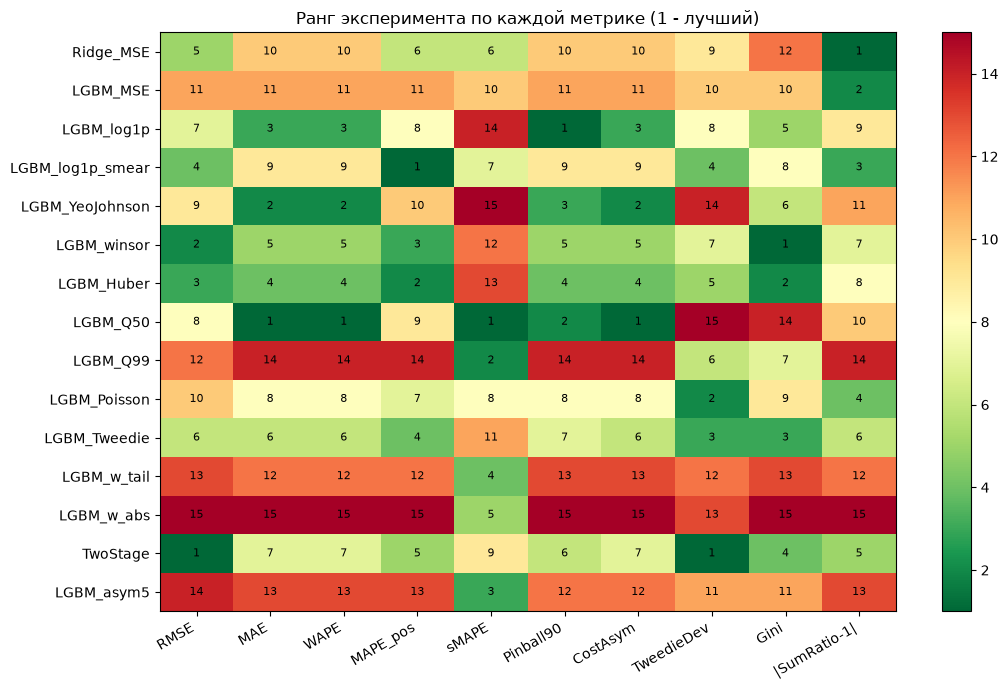

In [12]:
fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(rk.values, cmap='RdYlGn_r', aspect='auto')
ax.set_xticks(range(rk.shape[1]), rk.columns, rotation=30, ha='right')
ax.set_yticks(range(rk.shape[0]), rk.index)
for i in range(rk.shape[0]):
    for j in range(rk.shape[1]):
        ax.text(j, i, rk.iat[i, j], ha='center', va='center', fontsize=8)
ax.set_title('Ранг эксперимента по каждой метрике (1 - лучший)')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'skewed_rank_heatmap.png', dpi=150)
plt.show()

### RMSE доминируется хвостом

RMSE по фолдам и RMSE после удаления **одной** крупнейшей выплаты из оценки.

In [13]:
big = np.argmax(y)
mask_wo = np.ones(len(y), bool); mask_wo[big] = False
rows = []
for name in ['Const_mean', 'Ridge_MSE', 'LGBM_MSE', 'LGBM_Tweedie', 'TwoStage', 'LGBM_log1p']:
    per_fold = [np.sqrt(np.mean((oof[name][fold_id == f] - y[fold_id == f]) ** 2)) for f in range(5)]
    rows.append({'model': name, **{f'RMSE fold{f}': v for f, v in enumerate(per_fold)},
                 'RMSE все': res.loc[name, 'RMSE'],
                 'RMSE без 1 выплаты': np.sqrt(np.mean((oof[name][mask_wo] - y[mask_wo]) ** 2)),
                 'MAE все': res.loc[name, 'MAE'],
                 'MAE без 1 выплаты': np.mean(np.abs(oof[name][mask_wo] - y[mask_wo]))})
tail_df = pd.DataFrame(rows).set_index('model')
tail_df.to_csv(config.RESULTS_DIR / 'skewed_rmse_tail.csv')
print(f"крупнейшая выплата: {y[big]:,.0f} € в фолде {fold_id[big]}")
print(tail_df.round(1))

крупнейшая выплата: 4,075,401 € в фолде 3
              RMSE fold0  RMSE fold1  RMSE fold2  RMSE fold3  RMSE fold4  RMSE все  RMSE без 1 выплаты  MAE все  MAE без 1 выплаты
model                                                                                                                             
Const_mean        2617.1      5721.2      1514.8     11190.6      1550.7    5822.6              3066.9    170.3              164.3
Ridge_MSE         2617.2      5720.8      1515.0     11190.3      1550.6    5822.4              3066.8    171.7              165.7
LGBM_MSE          2675.8      5741.9      1623.3     11193.3      1649.8    5844.3              3108.8    186.5              180.5
LGBM_Tweedie      2618.4      5721.1      1515.9     11189.7      1551.0    5822.4              3067.2    139.8              133.7
TwoStage          2616.3      5720.6      1513.6     11188.5      1550.1    5821.5              3066.2    141.9              135.9
LGBM_log1p        2618.2      5722.1     

## 4. Сегментный анализ ошибки: нули / bulk / tail

- **zero** - полисы без выплат (96%);
- **bulk** - ненулевые выплаты до q90 ненулевых (обычные убытки);
- **tail** - верхние 10% ненулевых выплат (крупные убытки).

Для каждого сегмента: MAE и **смещение** mean(ŷ − y) (минус - недооценка).

In [14]:
q90_pos = np.quantile(y[y > 0], 0.90)
segment = np.where(y == 0, 'zero', np.where(y <= q90_pos, 'bulk', 'tail'))
print(f"граница bulk / tail: {q90_pos:,.0f} €")
print(pd.Series(segment).value_counts().to_dict())

seg_rows = []
for name in EXPERIMENTS:
    for s in ['zero', 'bulk', 'tail']:
        m = segment == s
        e = oof[name][m] - y[m]
        seg_rows.append({'model': name, 'segment': s, 'MAE': np.mean(np.abs(e)), 'bias': np.mean(e),
                         'share_pred': oof[name][m].sum() / oof[name].sum(), 'share_true': y[m].sum() / y.sum()})
seg = pd.DataFrame(seg_rows)
seg.to_csv(config.RESULTS_DIR / 'skewed_segments.csv', index=False)

seg_mae = seg.pivot(index='model', columns='segment', values='MAE')[['zero', 'bulk', 'tail']].loc[EXPERIMENTS]
seg_bias = seg.pivot(index='model', columns='segment', values='bias')[['zero', 'bulk', 'tail']].loc[EXPERIMENTS]
print("\nMAE по сегментам:")
print(seg_mae.round(1))
print("\nСмещение mean(ŷ − y) по сегментам:")
print(seg_bias.round(1))
for s in ['zero', 'bulk', 'tail']:
    print(f"лучший MAE в сегменте {s:4}: {seg_mae.loc[models_only, s].idxmin()}")

граница bulk / tail: 3,000 €
{'zero': 653047, 'bulk': 22484, 'tail': 2460}


/tmp/ipykernel_1732/569201130.py:12: RuntimeWarning: invalid value encountered in scalar divide
  'share_pred': oof[name][m].sum() / oof[name].sum(), 'share_true': y[m].sum() / y.sum()})



MAE по сегментам:
segment             zero    bulk     tail
model                                    
Const_mean          88.4   979.8  14531.8
Const_zero           0.0  1064.9  14620.3
Ridge_MSE           90.9   951.6  14494.4
LGBM_MSE           104.7  1001.1  14470.8
LGBM_log1p           0.3  1063.7  14619.2
LGBM_log1p_smear    71.1   960.4  14511.2
LGBM_YeoJohnson      0.0  1064.9  14620.2
LGBM_winsor         53.9   960.1  14512.7
LGBM_Huber          44.7   972.7  14529.3
LGBM_Q50             0.0  1064.8  14620.2
LGBM_Q99          1245.8   972.2  12842.8
LGBM_Poisson        70.6   961.6  14491.2
LGBM_Tweedie        57.4   960.0  14503.5
LGBM_w_tail        415.4  1048.3  14307.7
LGBM_w_abs        6941.6  8744.2  18933.6
TwoStage            60.0   950.0  14490.9
LGBM_asym5         446.5  1083.3  14302.9

Смещение mean(ŷ − y) по сегментам:
segment             zero    bulk     tail
model                                    
Const_mean          88.4  -976.5 -14531.8
Const_zero           

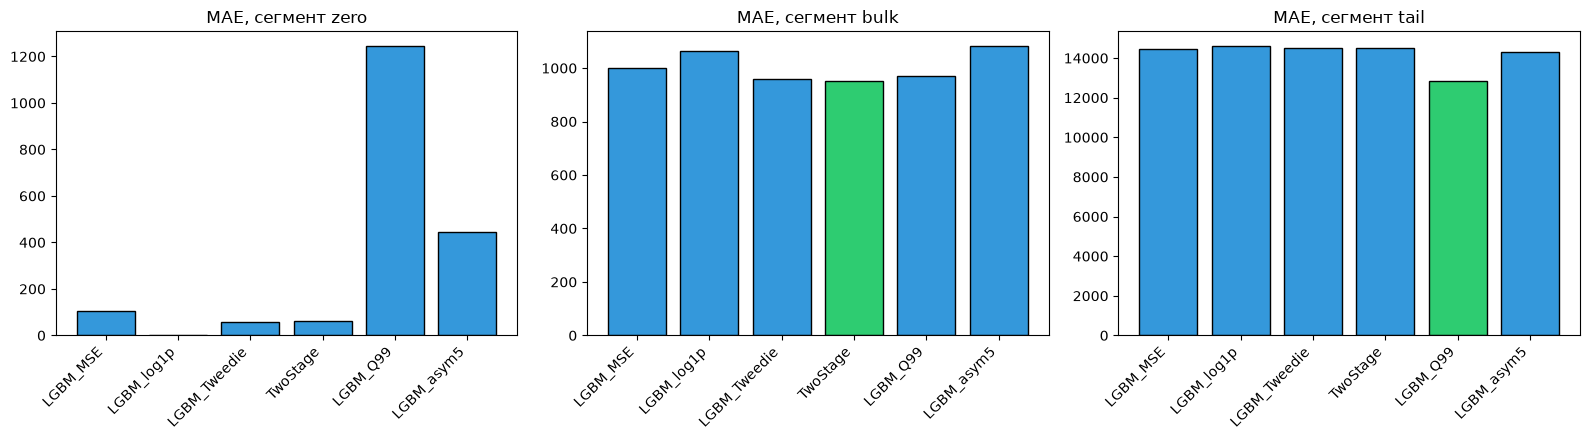

In [15]:
SHOW = ['LGBM_MSE', 'LGBM_log1p', 'LGBM_Tweedie', 'TwoStage', 'LGBM_Q99', 'LGBM_asym5']
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, s in zip(axes, ['zero', 'bulk', 'tail']):
    vals = seg_mae.loc[SHOW, s]
    ax.bar(range(len(SHOW)), vals, color=['#2ecc71' if v == vals.min() else '#3498db' for v in vals], edgecolor='black')
    ax.set_xticks(range(len(SHOW)), SHOW, rotation=45, ha='right')
    ax.set_title(f'MAE, сегмент {s}')
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'skewed_segments.png', dpi=150)
plt.show()

### Калибровка прогноза: средний прогноз vs средний факт по децилям прогноза

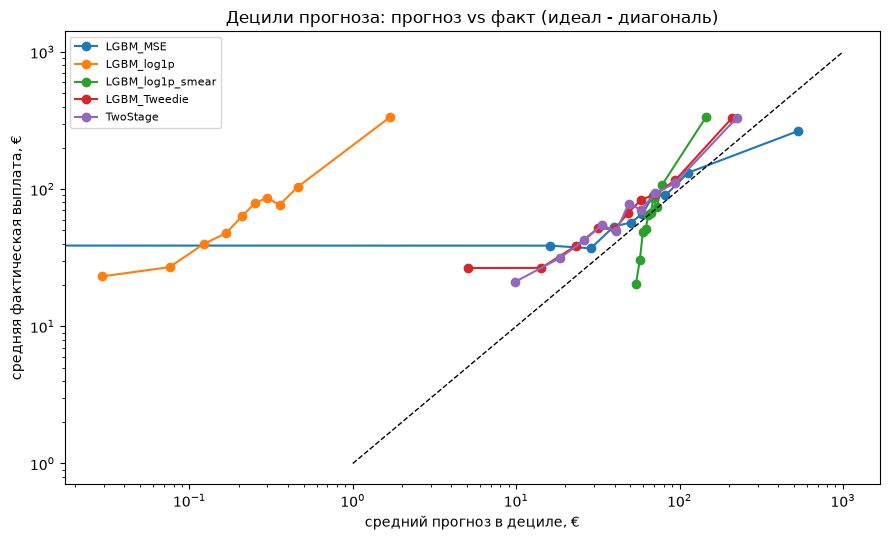

In [16]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for name in ['LGBM_MSE', 'LGBM_log1p', 'LGBM_log1p_smear', 'LGBM_Tweedie', 'TwoStage']:
    dec = pd.qcut(pd.Series(oof[name]).rank(method='first'), 10, labels=False)
    g = pd.DataFrame({'p': oof[name], 'y': y, 'd': dec}).groupby('d').mean()
    ax.plot(g['p'], g['y'], 'o-', label=name)
lim = [1, 1000]
ax.plot(lim, lim, 'k--', lw=1)
ax.set(xscale='log', yscale='log', xlabel='средний прогноз в дециле, €', ylabel='средняя фактическая выплата, €',
       title='Децили прогноза: прогноз vs факт (идеал - диагональ)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'skewed_decile_calibration.png', dpi=150)
plt.show()

## 5. Методы прерывистого спроса (Croston, SBA, TSB)

Croston, SBA (поправка Syntetos-Boylan) и TSB предназначены для **временных рядов** с большим числом нулевых периодов
(прерывистый спрос). Применимость проверяем по классификации Syntetos-Boylan: ADI (средний интервал между ненулевыми
продажами) > 1.32 означает прерывистый спрос.

- freMTPL2 - не временной ряд (по одной записи на полис), методы неприменимы;
- в нашем ряду спроса (04_demand) считаем ADI по всем 500 парам магазин-товар.

In [17]:
dem = pd.read_csv(config.path_demand)
adi = dem.groupby(['store', 'item'])['sales'].apply(lambda s: len(s) / (s > 0).sum())
cv2 = dem[dem['sales'] > 0].groupby(['store', 'item'])['sales'].apply(lambda s: (s.std() / s.mean()) ** 2)
print(f"нулевых продаж: {(dem['sales'] == 0).sum()} из {len(dem)}")
print(f"ADI: min {adi.min():.4f}, max {adi.max():.4f}  (порог прерывистости 1.32)")
print(f"CV² ненулевых: медиана {cv2.median():.3f} (порог 0.49)")
print(f"пар с прерывистым спросом (ADI > 1.32): {(adi > 1.32).sum()} из {len(adi)}")

нулевых продаж: 1 из 913000
ADI: min 1.0000, max 1.0005  (порог прерывистости 1.32)
CV² ненулевых: медиана 0.081 (порог 0.49)
пар с прерывистым спросом (ADI > 1.32): 0 из 500


## Выводы

**Диагностика.** 677 991 полис, 96.3% без выплат; skewness 549.5, эксцесс 363 244; медиана ненулевой выплаты 1 172 €,
максимум 4 075 401 €. Верхний 1% выплат даёт 37.9% всей суммы, одна крупнейшая - 6.8%.

- **Гетероскедастичность:** классический Breusch-Pagan отвергает H₀ (p ≈ 0, и по признакам, и по прогнозу),
  а робастный вариант Коэнкера - нет (p = 0.96); White - p = 0.057. Классический тест предполагает нормальность ошибок,
  а Jarque-Bera остатков = 5·10¹⁰. При таком эксцессе его «значимость» - артефакт хвостов. Неоднородность ошибки по величине y
  очевидна на графике |ошибка| vs y, но формально робастным тестом по признакам не подтверждается: признаки почти не объясняют
  дисперсию (R² OLS = 0.0025).
- **QQ-plot** - остатки далеки от нормальных; **Cook's distance:** 300 влиятельных объектов (D > 4/n), **все** - с выплатами,
  медиана выплаты у 10 самых влиятельных - 39 тыс. €.

### 1. RMSE доминируется хвостом и не различает модели

RMSE всех разумных моделей 5 821-5 844 - практически как у константы «среднее» (5 823). RMSE по фолдам: от 1 515 до 11 191;
в фолде 3 находится одна выплата 4.08 млн €, и **удаление одного полиса из оценки уменьшает RMSE почти вдвое**
(5 822 -> 3 067). Модель, оптимизированная под MSE (LGBM_MSE), даже хуже константы по RMSE (5 844) - подгоняется под гигантов.

### 2. MAE / WAPE / sMAPE выбирают «прогноз 0»

Оптимум MAE - медиана, а медиана при 96% нулей = 0. Поэтому лучшие по MAE, WAPE и sMAPE - `LGBM_Q50` и константа 0,
которые не собирают ни одного евро премии (Σŷ/Σy = 0.000). Асимметричная линейная стоимость (недооценка × 5) имеет оптимум
в 5/6-квантиле, а он тоже 0, - поэтому и по ней лучшая модель - «ноль». **Метрика на уровне отдельного полиса здесь не отражает
бизнес-задачу**: премия должна покрывать **ожидаемый** убыток портфеля.

### 3. MAPE ломается на нулях

sklearn-MAPE на нулях = 3·10¹³ - 5·10¹⁹ у всех моделей (деление на машинный эпсилон); MAPE только по y > 0 различает модели,
но игнорирует 96% полисов.

### 4. Рейтинг зависит от метрики

| Метрика | Лидер |
|---|---|
| RMSE, девиация Tweedie | TwoStage |
| MAE, WAPE, sMAPE, CostAsym | LGBM_Q50 (= прогноз 0) |
| Pinball(0.9) | LGBM_log1p |
| MAPE (y > 0) | LGBM_log1p_smear |
| Gini (ранжирование) | LGBM_winsor |
| Σŷ/Σy ≈ 1 | Ridge_MSE |

### 5. Преобразования таргета

- **log1p без поправки:** ранжирует хорошо (Gini 0.437 против 0.340 у LGBM_MSE), но прогноз - это медиана на лог-шкале:
  Σŷ/Σy = **0.004**. Это ловушка «обучить на log и вернуть expm1».
- **Smearing-поправка Дуана** возвращает уровень до Σŷ/Σy = 0.825 и даёт одну из лучших девиаций Tweedie (60.8).
- **Yeo-Johnson** - ещё хуже log1p (Σŷ/Σy = 0.0001). Box-Cox неприменим (нули).
- **Винзоризация q99.9:** лучший Gini (0.447), но Σŷ/Σy = 0.633 - срезана треть убытков: «крещение» хвоста убивает
  нужный сигнал, если цель - покрыть убытки.

### 6. Функции потерь и веса

- **Poisson, Tweedie, TwoStage** - лучшие девиации (59.1-60.8 против 672.6 у MSE) и высокий Gini (0.396-0.444).
  Но вне фолда сумма занижена (Σŷ/Σy 0.67-0.82): гигантские выплаты попадают в отдельные листья и не «размазываются»
  по портфелю. На практике нужна перекалибровка уровня (balance correction) - в работе не проверялась.
- **Huber** (δ = 3 000 €) - хорошее ранжирование (Gini 0.446), но Σŷ/Σy = 0.527.
- **Квантиль 0.99** - лучший MAE на хвосте (12 843 против 14 471 у MSE), но завышает портфель в 14 раз.
- **Веса** w = 1 + 4·I[y > q95] и w ∝ y завышают сумму в 4 и 48 раз: веса меняют **оцениваемую величину** (взвешенное
  среднее ≠ среднее). Отрицательный результат.
- **Асимметричная квадратичная потеря** (недооценка × 5) делает то, что обещает: смещение на bulk −335 € против −900 € у MSE,
  но завышает портфель в 4.85 раза и проигрывает по линейной асимметричной стоимости - функция потерь при обучении
  и метрика оценки должны совпадать.

### 7. Сегменты: модель A лучше на bulk, модель B - на хвосте

MAE: на нулях лучше всех `LGBM_Q50` (0), на обычных выплатах (bulk, до 3 000 €) - `TwoStage` (950 €), на крупных (tail) -
`LGBM_Q99` (12 843 €). Одной «лучшей» модели нет - выбор определяется тем, какой сегмент важнее бизнесу.

### 8. Croston / SBA / TSB неприменимы

freMTPL2 не временной ряд. В ряду спроса 04_demand ADI = 1.000-1.0005 у всех 500 пар (порог прерывистости 1.32),
CV² = 0.08 - спрос «гладкий», единственный ноль на 913 000 наблюдений. Методы прерывистого спроса здесь не нужны.

### Порядок действий

**Диагностировать скошенность -> выбрать метрику под бизнес-цель** (для премии: девиация Tweedie/Poisson + Gini + Σŷ/Σy)
**-> выбрать функцию потерь под метрику** (Tweedie / Poisson / частота × тяжесть) **-> только потом модель.**
RMSE, MAE и MAPE на таком таргете выбирают бесполезные модели.